# Human PBMCs (10X Genomics)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2024-10-30
> - Modified: 2025-12-21
> - https://www.10xgenomics.com/cn/datasets/20k_Human_Donor1-4_PBMC_3p_gem-x_multiplex

# Experimental Design

| Sample | Cell/Tissue | Organism | Full name | Gender | Age | Disease status | Library | Source |
| - | - | - | - | - | - | - | - | - |
| Donors 1~4 | PBMCs | Homo sapiens | Peripheral blood mononuclear cells | Male | 18~35 | Healthy | 10X 3' V4 scRNA-seq | Cellular Technologies Limited |
| Donors 1~4 | PBMCs | Homo sapiens | Peripheral blood mononuclear cells | Female | 36-50 | Healthy | 10X 3' V4 scRNA-seq | Cellular Technologies Limited |

> - GEM-X Universal 3' Gene Expression v4 4-plex On-chip Multiplexing (CG000768)
> - Illumina NovaSeq 6000
> - cellranger multi

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(Seurat))
suppressPackageStartupMessages(library(cowplot))

── Attaching core tidyverse packages ──────────────────────────────────────────────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.2
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


# 1. Data Import

In [2]:
data_dir <- "~/data1/single_cell_dataset/dataset_10xGenomics/Hs_PBMCs_3Pv4_20k"

In [68]:
sc.comb <- readRDS(
    file.path(data_dir, "result", "s3_normalization_seurat_V5.rds"))

# 4. Dimensionality Reduction

In [69]:
sc.comb <- RunPCA(
    sc.comb, features = VariableFeatures(sc.comb), 
    npcs = 50, verbose = FALSE)

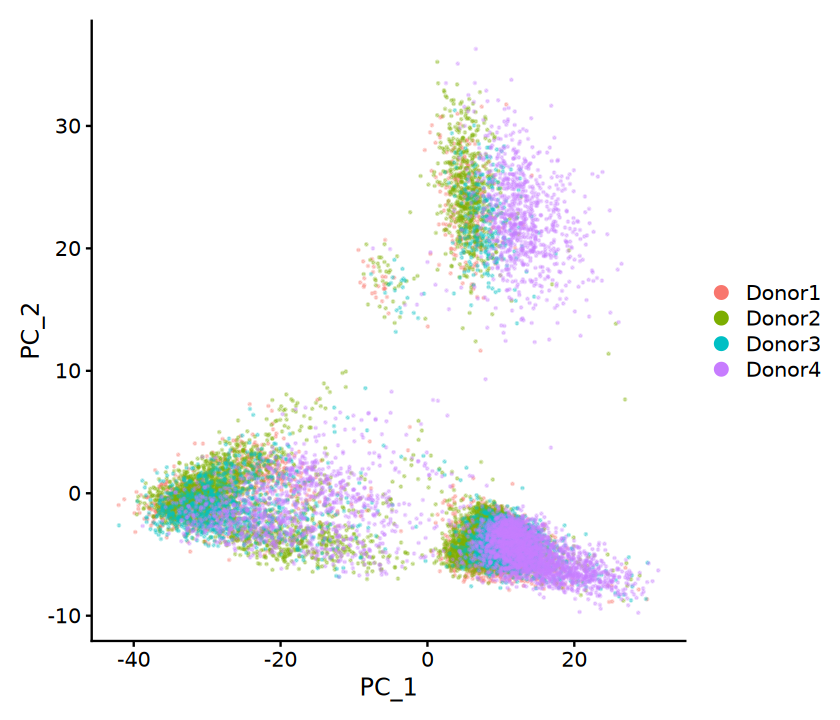

In [70]:
options(repr.plot.width = 7, repr.plot.height = 6)
DimPlot(sc.comb, reduction = "pca", alpha = 0.3)

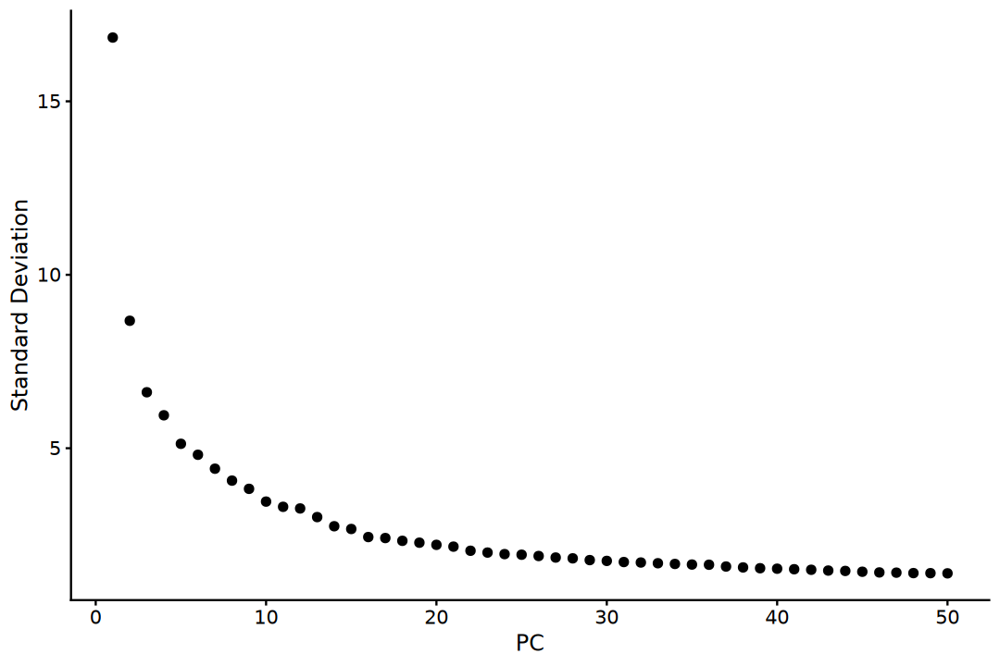

In [71]:
options(repr.plot.width = 9, repr.plot.height = 6)
ElbowPlot(sc.comb, ndims = 50)

In [72]:
# Estimating PCA dimensionality
pca_var <- sc.comb@reductions$pca@stdev^2
pca_con <- pca_var / sum(pca_var)
nPCs <- which(cumsum(pca_con) > 0.9 & pca_con < 0.05)[1]
print(nPCs)

[1] 24


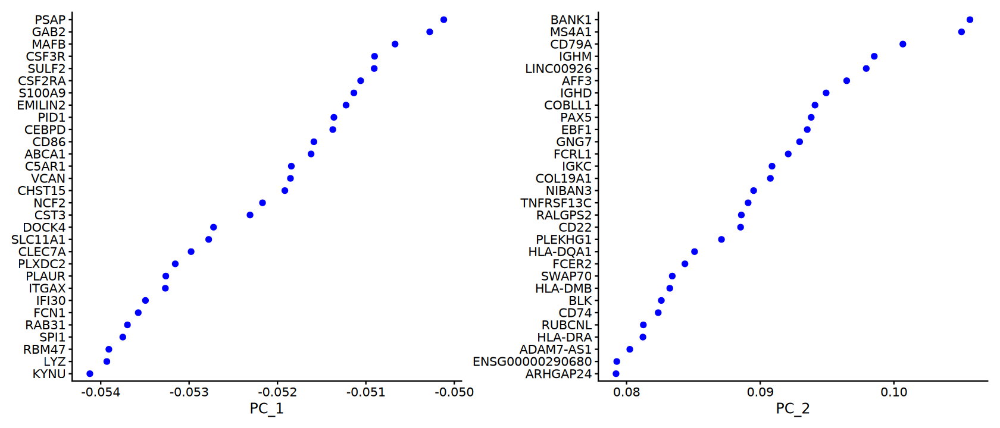

In [73]:
options(repr.plot.width = 14, repr.plot.height = 6)
VizDimLoadings(sc.comb, dims = 1:2, reduction = "pca", ncol = 2)

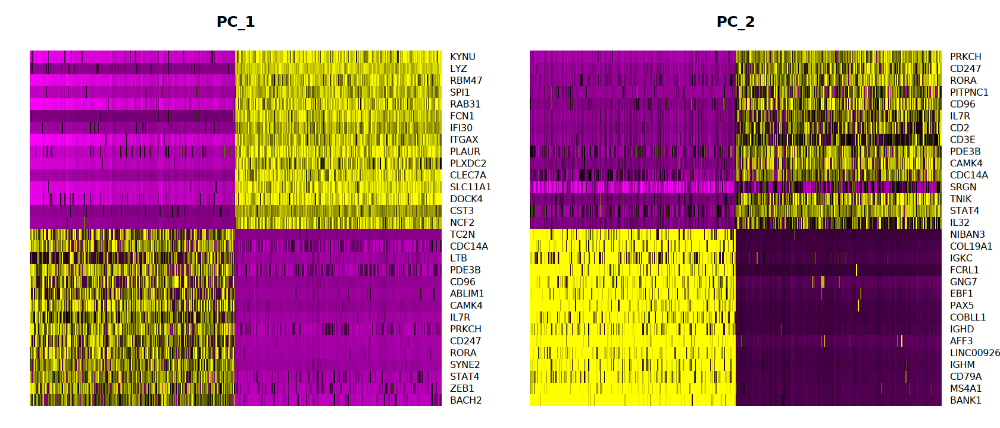

In [74]:
options(repr.plot.width = 14, repr.plot.height = 6)
DimHeatmap(sc.comb, dims = 1:2, cells = 500, balanced = TRUE)

In [75]:
npcs_clusters <- function (
    obj, method = c("umap", "tsne"), reduction, 
    dims = c(10, 20, 25, 30, 40, 50), resolution = 0.5) {

    method <- match.arg(method)
    plot_list <- list()
    
    for (dim in dims) {
        obj <- FindNeighbors(
            obj, reduction = reduction, dims = 1:dim, verbose = FALSE)
        obj <- FindClusters(
            obj, resolution = resolution, verbose = FALSE)
        if (method == "umap") {
            # UMAP
            obj <- RunUMAP(
                obj, dims = 1:dim, reduction = reduction, verbose = FALSE)
            plot_list[[paste0("nPCs_", dim)]] <- DimPlot(
                obj, reduction = "umap", group.by = "seurat_clusters", 
                label = TRUE, label.size = 6, repel = FALSE) +
                ggtitle(paste0("UMAP, nPCs = ", dim))
        } else if (method == "tsne") {
            # t-SNE
            obj <- RunTSNE(
                obj, dims = 1:dim, reduction = reduction, verbose = FALSE)
            plot_list[[paste0("nPCs_", dim)]] <- DimPlot(
                obj, reduction = "tsne", group.by = "seurat_clusters", 
                label = TRUE, label.size = 6, repel = FALSE) +
                ggtitle(paste0("t-SNE, nPCs = ", dim))
        }
    }
    return(plot_list)
}

In [76]:
plot_list <- npcs_clusters(
    sc.comb, method = "umap", reduction = "pca")

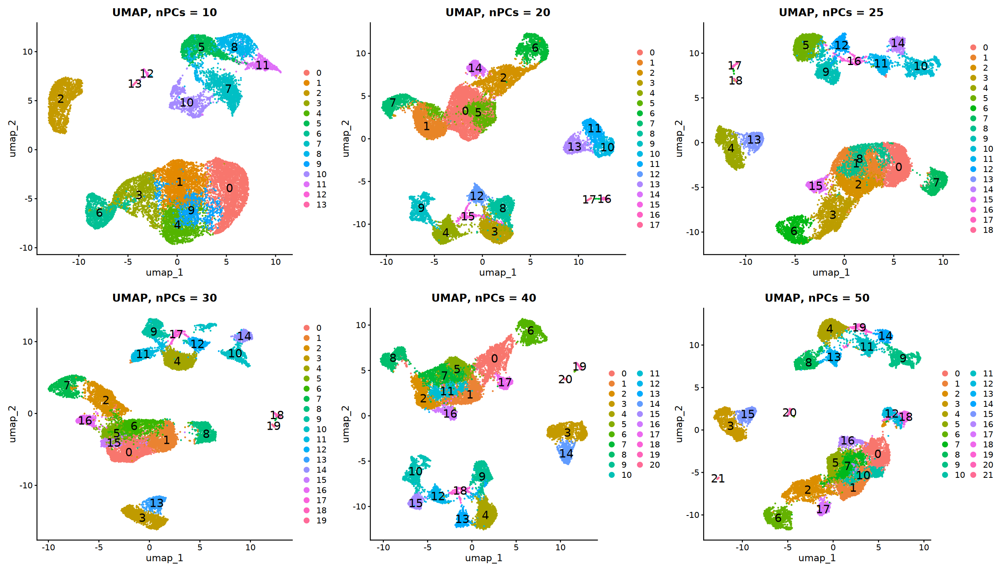

In [77]:
options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plotlist = plot_list, ncol = 3)

In [78]:
nPCs <- 30

# 5. Integration

In [79]:
sc.comb

An object of class Seurat 
52683 features across 17434 samples within 2 assays 
Active assay: RNA (27812 features, 3000 variable features)
 9 layers present: counts.Donor1, counts.Donor2, counts.Donor3, counts.Donor4, data.Donor1, data.Donor2, data.Donor3, data.Donor4, scale.data
 1 other assay present: SCT
 1 dimensional reduction calculated: pca

## 1). CCA
Anchor-based canonical correlation analysis integration

Seurat uses CCA to find the way maximizing the similarities between data sets. Next, Seurat introduces an anchoring mechanism, looking for cell anchors in the two data sets. Cell anchors are cell pairs with each cell in a different data set. The two cells are one of the nearest neighbors of each other in the CCA space, while the nearest neighbors of one cell in its own data set also tend to be neighbors of the nearest neighbors of the other cell of the cell pair. The two anchored cells are seen as corresponding cells from one data set to the other, and an integration procedure is then applied by subtracting expression of one data set by the transformation matrix calculated by comparing the anchoring cell pairs in the two data sets.

In [80]:
sc.inte <- IntegrateLayers(
    sc.comb, method = CCAIntegration, orig.reduction = "pca", 
    new.reduction = "cca", verbose = FALSE)
sc.inte

An object of class Seurat 
52683 features across 17434 samples within 2 assays 
Active assay: RNA (27812 features, 3000 variable features)
 9 layers present: counts.Donor1, counts.Donor2, counts.Donor3, counts.Donor4, data.Donor1, data.Donor2, data.Donor3, data.Donor4, scale.data
 1 other assay present: SCT
 2 dimensional reductions calculated: pca, cca

## 2). RPCA

In [81]:
options(future.globals.maxSize = 24 * 1024^3)

In [82]:
sc.inte <- IntegrateLayers(
    sc.inte, method = RPCAIntegration, orig.reduction = "pca",
    new.reduction = "rpca", verbose = FALSE)
sc.inte

An object of class Seurat 
52683 features across 17434 samples within 2 assays 
Active assay: RNA (27812 features, 3000 variable features)
 9 layers present: counts.Donor1, counts.Donor2, counts.Donor3, counts.Donor4, data.Donor1, data.Donor2, data.Donor3, data.Donor4, scale.data
 1 other assay present: SCT
 3 dimensional reductions calculated: pca, cca, rpca

## 3). Harmony

Harmony uses fuzzy clustering to assign every cell to multiple clusters. For each cluster, it then calculates a correction factor for each data set to move the centroid of the cluster of this data set towards the global centroid of the cluster. Since every cell is represented as a combination of multiple clusters, a cell-specific correction factor is calculated by averaging the correction factors of clusters that the cell belongs to while weighting by the cluster assignment ratio. This process will be iterated until convergence happens or reaching the iteration limits.

In [83]:
suppressPackageStartupMessages(library(harmony))

In [84]:
sc.inte <- RunHarmony(sc.inte, "orig.ident", verbose = FALSE)
sc.inte

An object of class Seurat 
52683 features across 17434 samples within 2 assays 
Active assay: RNA (27812 features, 3000 variable features)
 9 layers present: counts.Donor1, counts.Donor2, counts.Donor3, counts.Donor4, data.Donor1, data.Donor2, data.Donor3, data.Donor4, scale.data
 1 other assay present: SCT
 4 dimensional reductions calculated: pca, cca, rpca, harmony

## 4). FastMNN

In [85]:
suppressPackageStartupMessages(library(SeuratWrappers))

In [86]:
sc.inte <- IntegrateLayers(
    sc.inte, method = FastMNNIntegration, orig.reduction = "pca",
    new.reduction = "mnn", verbose = FALSE)
sc.inte

Warning message:
“Layer counts isn't present in the assay object; returning NULL”


An object of class Seurat 
54683 features across 17434 samples within 3 assays 
Active assay: RNA (27812 features, 3000 variable features)
 9 layers present: counts.Donor1, counts.Donor2, counts.Donor3, counts.Donor4, data.Donor1, data.Donor2, data.Donor3, data.Donor4, scale.data
 2 other assays present: SCT, mnn.reconstructed
 5 dimensional reductions calculated: pca, cca, rpca, harmony, mnn

## 5). scVI

In [87]:
suppressPackageStartupMessages(library(SeuratWrappers))

In [88]:
sc.inte <- IntegrateLayers(
    sc.inte, method = scVIIntegration, 
    new.reduction = "scvi", 
    conda_env = "~/miniconda3/envs/r452")
sc.inte

An object of class Seurat 
54683 features across 17434 samples within 3 assays 
Active assay: RNA (27812 features, 3000 variable features)
 9 layers present: counts.Donor1, counts.Donor2, counts.Donor3, counts.Donor4, data.Donor1, data.Donor2, data.Donor3, data.Donor4, scale.data
 2 other assays present: SCT, mnn.reconstructed
 6 dimensional reductions calculated: pca, cca, rpca, harmony, mnn, scvi

## 6). LIGER
Linked Inference of Genomic Experimental Relationships

In [89]:
suppressPackageStartupMessages(library(rliger))

In [90]:
sc.liger <- sc.inte |>
    normalize(verbose = FALSE) |>
    selectGenes(verbose = FALSE) |>
    scaleNotCenter(verbose = FALSE) |>
    runINMF(k = nPCs, lambda = 5, 
            datasetVar = "orig.ident",
            verbose = FALSE, seed = 1234) |>
    quantileNorm()
sc.liger

An object of class Seurat 
54683 features across 17434 samples within 3 assays 
Active assay: RNA (27812 features, 14169 variable features)
 17 layers present: counts.Donor1, counts.Donor2, counts.Donor3, counts.Donor4, data.Donor1, data.Donor2, data.Donor3, data.Donor4, scale.data, ligerNormData.Donor1, ligerNormData.Donor2, ligerNormData.Donor3, ligerNormData.Donor4, ligerScaleData.Donor1, ligerScaleData.Donor2, ligerScaleData.Donor3, ligerScaleData.Donor4
 2 other assays present: SCT, mnn.reconstructed
 8 dimensional reductions calculated: pca, cca, rpca, harmony, mnn, scvi, inmf, inmfNorm

In [91]:
sc.inte@reductions$ligerInmf <- sc.liger@reductions$inmfNorm

## Others
RSS, one of the concept is, if there is a reference data set with multiple sample, where differences among those samples contain information of the cell type heterogeneity in the samples, representing each cell by its transcriptome similarities to those reference samples rather than its transcriptome profile itself may efficiently clean up technical noise while preserving the essential information. The method derived from this concept is called reference component analysis (RCA) or reference similarity spectrum.

cluster similarity spectrum (CSS). it firstly does cell clustering to scRNA-seq data of each sample to be integrated, and uses the average expression profiles of the resulted clusters as the reference to calculate these similarities.

## Evaluation Integration (Part 1)

Methods:
1. Removal of batch effects
    1. k-nearest-neighbor batch effect test (kBET)
    2. k-nearest-neighbor (kNN) graph connectivity
    3. average silhouette width (ASW) across batches: The silhouette width measures the relationship between the within-cluster distances of a cell and the between-cluster distances of that cell to the closest cluster
    4. integration local inverse Simpson’s Index
       - graph iLISI
    5. PCA regression
2. Conservation of biological variance
    1. integration local inverse Simpson’s Index
       - graph cLISI
    2. adjusted Rand Index (ARI): The Rand index compares the overlap of two clusterings
    3. normalized mutual information (NMI): NMI compares the overlap of two clusterings
    4. relative distances (cell-type ASW)
    5. cell-cycle variance conservation
    6. overlaps of highly variable genes (HVGs) per batch before and after integration
    7. conservation of trajectories

Tools:
1. SeuratIntegrate

Reference:
- Tran, H.T.N., Ang, K.S., Chevrier, M. et al. A benchmark of batch-effect correction methods for single-cell RNA sequencing data. Genome Biol 21, 12 (2020). https://doi.org/10.1186/s13059-019-1850-9
- Ruben Chazarra-Gil, Stijn van Dongen, Vladimir Yu Kiselev, Martin Hemberg, Flexible comparison of batch correction methods for single-cell RNA-seq using BatchBench, Nucleic Acids Research, Volume 49, Issue 7, 19 April 2021, Page e42, https://doi.org/10.1093/nar/gkab004
- Luecken, M.D., Büttner, M., Chaichoompu, K. et al. Benchmarking atlas-level data integration in single-cell genomics. Nat Methods 19, 41–50 (2022). https://doi.org/10.1038/s41592-021-01336-8
- Huawen Zhong, Wenkai Han, David Gomez-Cabrero, Jesper Tegner, Xin Gao, Guoxin Cui, Manuel Aranda, Benchmarking cross-species single-cell RNA-seq data integration methods: towards a cell type tree of life, Nucleic Acids Research, Volume 53, Issue 1, 13 January 2025, gkae1316, https://doi.org/10.1093/nar/gkae1316

PCA regression

In [92]:
lm_res <- map(names(sc.inte@reductions), function(rdc) {
    map(1:nPCs, function(pc) {
        fit <- lm(Embeddings(sc.inte, reduction = rdc)[, pc] ~ 
                  sc.inte$orig.ident)
        s <- summary(fit)
        data.frame(reduction = rdc, PC = pc, 
                   r.squared = s$r.squared,
                   adj.r.squared = s$adj.r.squared)
    }) |> bind_rows()
}) |> bind_rows()

In [93]:
mean_r2 <- lm_res |>
    group_by(reduction) |>
    summarise(mean_r.squared = mean(r.squared), 
              .groups = "drop") |>
    mutate(mean_r.squared = round(mean_r.squared, 4)) |>
    arrange(mean_r.squared)

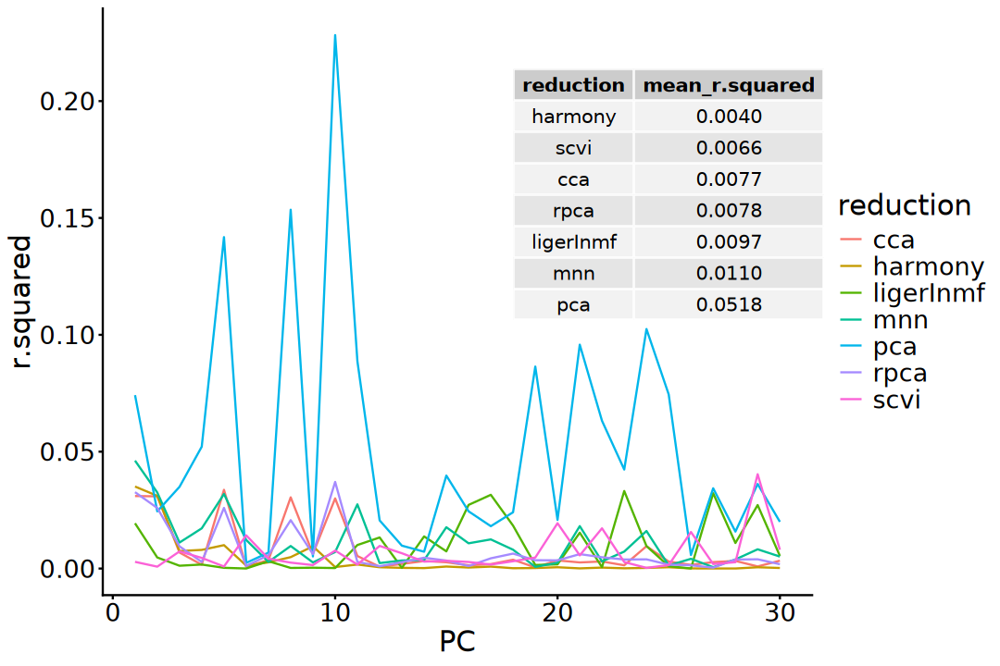

In [94]:
options(repr.plot.width = 9, repr.plot.height = 6)
p <- ggplot(lm_res, aes(x = PC, y = r.squared, color = reduction)) +
    geom_line() +
    theme_classic() + 
    theme(plot.title = element_text(size = 20, hjust = 0.5), 
          axis.title = element_text(size = 18),
          axis.text = element_text(size = 16),
          legend.title = element_text(size = 18),
          legend.text = element_text(size = 16))

# tbl <- ggpubr::ggtexttable(mean_r2, rows = NULL, theme = ggpubr::ttheme("light"))
tbl <- gridExtra::tableGrob(mean_r2, rows = NULL)
p + annotation_custom(grob = tbl, xmin = 20, xmax = 30,
                      ymin = 0.11, ymax = 0.21)

Local Inverse Simpson’s Index (LISI)

1. integration LISI (iLISI)
2. cell type LISI(cLISI)

In [95]:
suppressPackageStartupMessages(library(lisi))

In [96]:
calculate_ilisi <- function(
    obj, reductions = NULL, index = "orig.ident") {
    
    reductions <- reductions %||% names(obj@reductions)
    reductions <- reductions[reductions %in% names(obj@reductions)]
    if (length(reductions) == 0) stop("No valid reductions found.")

    map(reductions, function(rdc) {
        compute_lisi(X = Embeddings(obj, reduction = rdc),
                     meta_data = obj@meta.data,
                     label_colnames = index) |>
            as_tibble(rownames = "cell") |>
            rename_with(~ paste0(rdc, "_", .x), -cell)
    }) |>
        purrr::reduce(left_join, by = "cell")
}

In [97]:
lisi_res <- calculate_ilisi(sc.inte)

In [98]:
lisi_long <- lisi_res |>
    pivot_longer(-cell, names_to = c("method", "index"),
                 names_sep = "_", values_to = "LISI") |>
    group_by(method, index) |>
    mutate(mean_LISI = mean(LISI)) |>
    ungroup() |>
    mutate(method = fct_reorder(method, mean_LISI, .fun = mean))

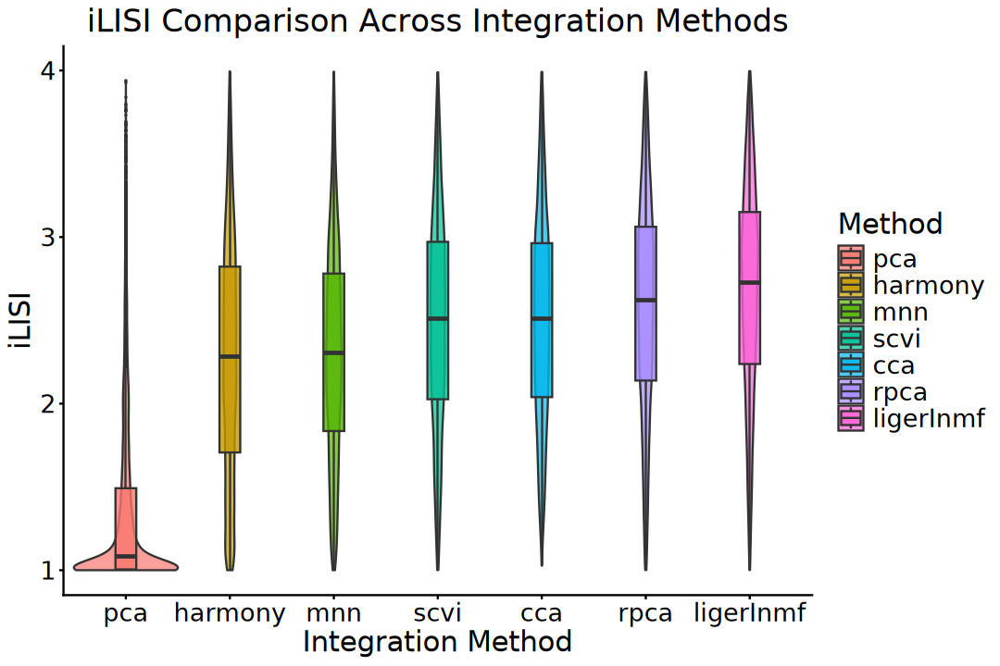

In [99]:
options(repr.plot.width = 9, repr.plot.height = 6)
ggplot(lisi_long, aes(x = method, y = LISI, fill = method)) +
    geom_violin(width = 1, alpha = 0.7) +
    geom_boxplot(width = 0.2, outlier.size = 0, alpha = 0.8) +
    labs(title = "iLISI Comparison Across Integration Methods",
         x = "Integration Method", y = "iLISI", fill = "Method") +
    theme_classic() + 
    theme(plot.title = element_text(size = 20, hjust = 0.5), 
          axis.title = element_text(size = 18),
          axis.text = element_text(size = 16),
          legend.title = element_text(size = 18),
          legend.text = element_text(size = 16))

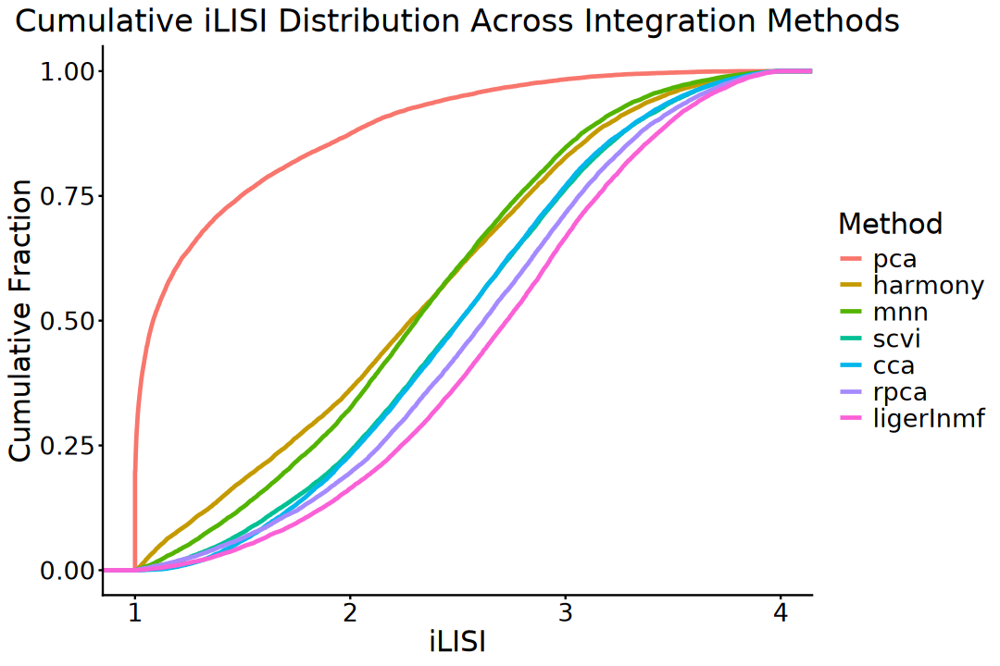

In [100]:
options(repr.plot.width = 9, repr.plot.height = 6)
ggplot(lisi_long, aes(x = LISI, color = method)) +
    stat_ecdf(linewidth = 1) +
    labs(title = "Cumulative iLISI Distribution Across Integration Methods",
         x = "iLISI", y = "Cumulative Fraction", color = "Method") +
    theme_classic() + 
    theme(plot.title = element_text(size = 20, hjust = 0.5), 
          axis.title = element_text(size = 18),
          axis.text = element_text(size = 16),
          legend.title = element_text(size = 18),
          legend.text = element_text(size = 16))

## Visualization

In [101]:
plot_inte_res <- function(obj, dims = 10, reduction) {
    
    obj <- RunUMAP(obj, dims = 1:dims, reduction = reduction, verbose = FALSE)
    obj <- RunTSNE(obj, dims = 1:dims, reduction = reduction, verbose = FALSE)

    p1 <- DimPlot(obj, reduction = reduction, group.by = "orig.ident", alpha = 0.1)
    p2 <- DimPlot(obj, reduction = "umap", group.by = "orig.ident", alpha = 0.1)
    p3 <- DimPlot(obj, reduction = "tsne", group.by = "orig.ident", alpha = 0.1)
    
    plot_grid(p1, p2, p3, ncol = 3)
}

In [102]:
methods <- c("pca", "cca", "harmony", "scvi", "ligerInmf")

pg_list <- lapply(methods, function(redu) {
    plot_inte_res(sc.inte, nPCs, redu)
})

In [103]:
titles <- c("non-integrate", "CCA", "Harmony", "scVI", "LIGER-Inmf")

title_list <- lapply(titles, function(text) {
    ggdraw() + draw_label(text, angle = 90, fontface = 'bold', size = 20)
})

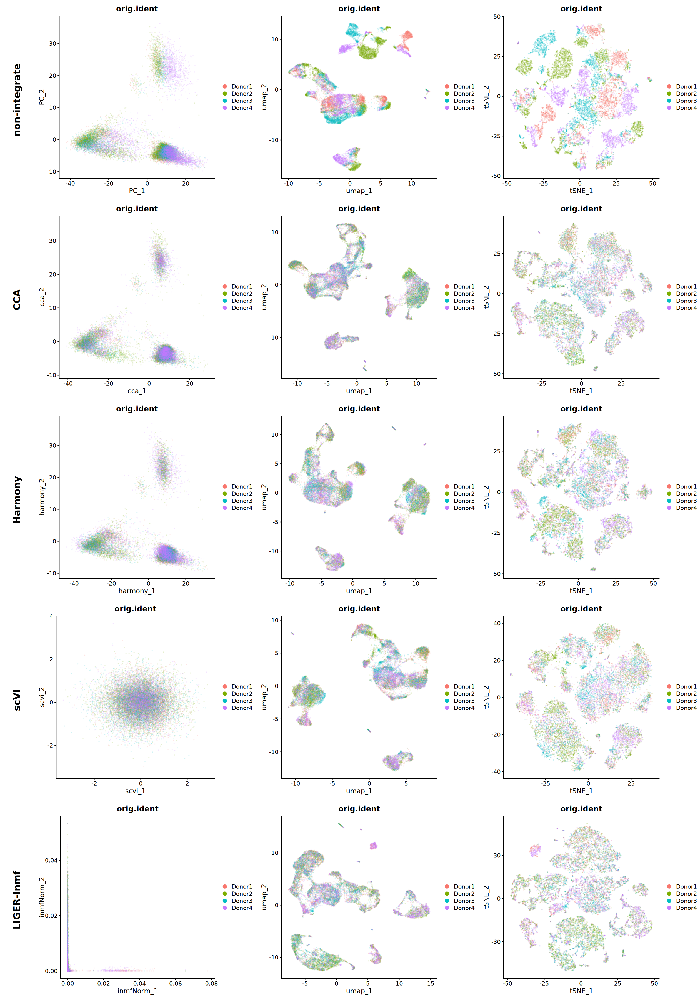

In [104]:
options(repr.plot.width = 21, repr.plot.height = 30)
plot_grid(
    plot_grid(plotlist = title_list, ncol = 1), 
    plot_grid(plotlist = pg_list, ncol = 1), 
    ncol = 2, rel_widths = c(0.05, 1))

In [105]:
inte_rdc <- "cca"

# 6. Clustering

In [106]:
sc.inte <- JoinLayers(sc.inte)
sc.inte

An object of class Seurat 
54683 features across 17434 samples within 3 assays 
Active assay: RNA (27812 features, 3000 variable features)
 3 layers present: data, counts, scale.data
 2 other assays present: SCT, mnn.reconstructed
 7 dimensional reductions calculated: pca, cca, rpca, harmony, mnn, scvi, ligerInmf

## 1). Non-linear embedding

In [99]:
sc.inte <- RunUMAP(
    sc.inte, dims = 1:nPCs, reduction = "pca", verbose = FALSE)

In [100]:
sc.inte <- RunTSNE(
    sc.inte, dims = 1:nPCs, reduction = "pca", verbose = FALSE)

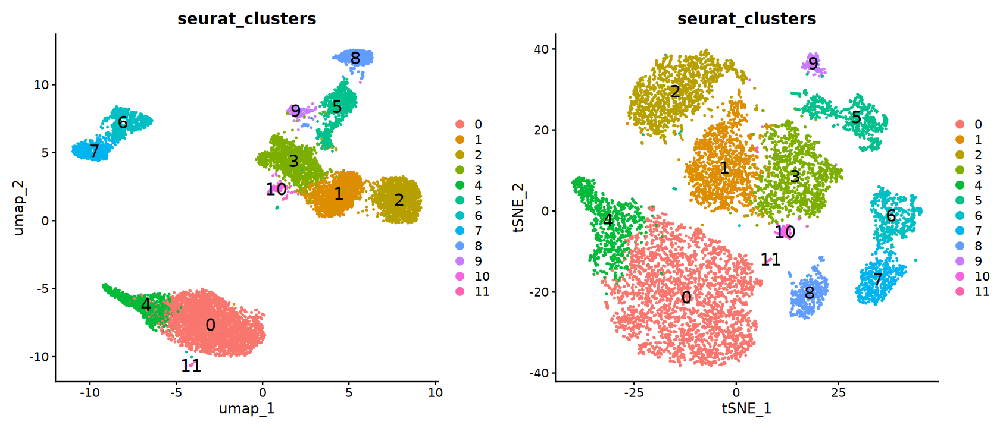

In [101]:
p1 <- DimPlot(sc.inte, reduction = "umap")
p2 <- DimPlot(sc.inte, reduction = "tsne")

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

## 1). kNN graph

In [107]:
sc.inte <- FindNeighbors(
    sc.inte, features = VariableFeatures(sc.inte), k.param = 20,
    reduction = inte_rdc, dims = 1:nPCs, verbose = FALSE)

## 2). Resolution tuning

In [108]:
suppressPackageStartupMessages(library(caret))
suppressPackageStartupMessages(library(rpart))
suppressPackageStartupMessages(library(clustree))

In [109]:
assess_resolution_by_tree <- function(
	obj, resolution, features = NULL, train_frac = 0.7, 
    maxdepth = 4, cp = 0.01, return_model = FALSE) {

	features <- features %||% VariableFeatures(obj)
    
	df <- LayerData(obj, features = features, layer = "data") |>
        t() |> data.frame()
	df$cluster <- as.factor(Idents(obj))

	idx <- createDataPartition(df$cluster, p = train_frac, list = FALSE)
	train <- df[idx, ]
	test <- df[-idx, ]

	fit <- rpart(
        cluster ~ ., data = train, method = "class",
        control = rpart.control(maxdepth = maxdepth, cp = cp))

	pred <- predict(fit, test, type = "class")
    
    f1 <- MLmetrics::F1_Score(
        y_pred = pred, y_true = test$cluster, positive = NULL)
    get_tree_depth <- function(fit) {
        fit$frame |> row.names() |> as.numeric() |> 
        max() |> log2() |> floor() |> (`+`)(1)
    }

	out <- list(
        resolution = resolution,
        accuracy = mean(pred == test$cluster),
        f1 = f1,
        tree_depth = get_tree_depth(fit),
        n_cluster = Idents(obj) |> levels() |> length()
    )

    if(return_model) out$model <- fit
    return(out)
}

In [110]:
resolution_clusters <- function (
    obj, reduction, dims = 10,
    resolution = seq(0.1, 0.9, 0.1), 
    plot_dir = NULL, 
    ncols = 3, widths = 21, heights = 18) {

    metrics_list <- list()
    plot_umap_list <- list()
    plot_tsne_list <- list()
    
    for (res in resolution) {
        obj <- FindClusters(obj, resolution = res, 
                            verbose = FALSE)
        # Metrics
        metrics_list[[paste0("res_", res)]] <- 
            assess_resolution_by_tree(obj, resolution = res)

        plot_umap_list[[paste0("res_", res)]] <- DimPlot(
            obj, reduction = "umap", group.by = "seurat_clusters", 
            label = TRUE, label.size = 6, repel = FALSE) +
            ggtitle(paste0("UMAP, res = ", res))

        plot_tsne_list[[paste0("res_", res)]] <- DimPlot(
            obj, reduction = "tsne", group.by = "seurat_clusters", 
            label = TRUE, label.size = 6, repel = FALSE) +
            ggtitle(paste0("t-SNE, res = ", res)) 
    }

    cluster_tree <- clustree(
        obj@meta.data, prefix = "RNA_snn_res.", node_text_size = 6) +
        theme(legend.title = element_text(size = 18), 
              legend.text = element_text(size = 16))
    
    if (!is.null(plot_dir)) {
        
        plot_umap_all <- plot_grid(plotlist = plot_umap_list, ncol = ncols)
        file.path(plot_dir, paste0("p6.1_UMAP_resolutions_", reduction, ".png")) |> 
            ggsave(plot = plot_umap_all, width = widths, height = heights)
        
        plot_tsne_all <- plot_grid(plotlist = plot_tsne_list, ncol = ncols)
        file.path(plot_dir, paste0("p6.2_tSNE_resolutions_", reduction, ".png")) |> 
            ggsave(plot = plot_tsne_all, width = widths, height = heights)
        
        file.path(plot_dir, paste0("p6.3_cluster_tree_", reduction, ".png")) |>
            ggsave(plot = cluster_tree, width = 12, height = 10)
    }
    
    return(list(metrics_list = metrics_list, 
                plot_umap_list = plot_umap_list,
                plot_tsne_list = plot_tsne_list,
                cluster_tree = cluster_tree))
}

In [111]:
cluster_list <- resolution_clusters(
    sc.inte, reduction = inte_rdc, dims = nPCs,
    resolution = seq(0.1, 0.9, 0.1),
    plot_dir = file.path(data_dir, "visualization"))

In [112]:
metrics_df <- do.call(rbind, lapply(cluster_list$metrics_list, as.data.frame)) |>
    mutate(accuracy = round(accuracy * 100, 2), 
           f1 = round(f1 * 100, 2))

metrics_df

,resolution,accuracy,f1,tree_depth,n_cluster
,<dbl>,<dbl>,<dbl>,<dbl>,<int>
res_0.1,0.1,73.14,77.87,5,11
res_0.2,0.2,69.09,72.56,5,14
res_0.3,0.3,63.16,70.97,5,16
res_0.4,0.4,63.64,72.97,5,16
res_0.5,0.5,54.24,91.56,5,18
res_0.6,0.6,53.90,91.72,5,19
res_0.7,0.7,54.56,91.88,5,19
res_0.8,0.8,54.75,91.36,5,20
res_0.9,0.9,43.41,41.46,5,23


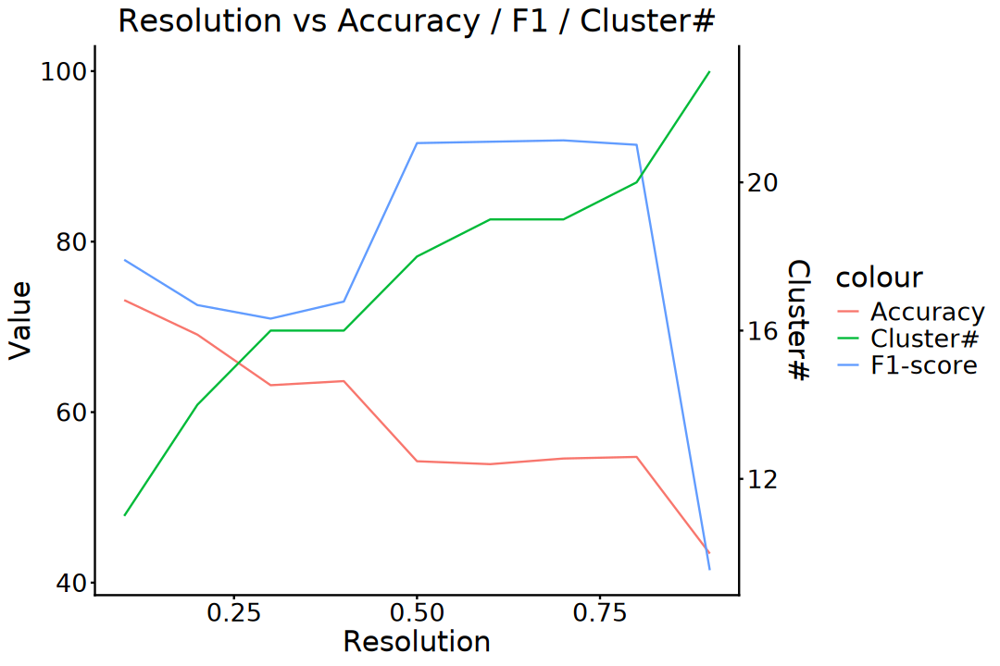

In [113]:
options(repr.plot.width = 9, repr.plot.height = 6)
ggplot(metrics_df, aes(x = resolution)) +
    geom_line(aes(y = accuracy, color = "Accuracy")) +
    geom_line(aes(y = f1, color = "F1-score")) +
    geom_line(aes(y = n_cluster/ max(n_cluster)*100, 
                  color = "Cluster#")) +
    scale_y_continuous(
        name = "Value", 
        sec.axis = sec_axis(
            ~./100*max(metrics_df$n_cluster), name = "Cluster#")) +
    ggtitle("Resolution vs Accuracy / F1 / Cluster#") + 
    labs(x = "Resolution") +
    theme_classic() +
    theme(plot.title =  element_text(size = 20, hjust = 0.5),
          axis.title = element_text(size = 18),
          axis.text = element_text(size = 16),
          legend.title = element_text(size = 18),
          legend.text = element_text(size = 16))

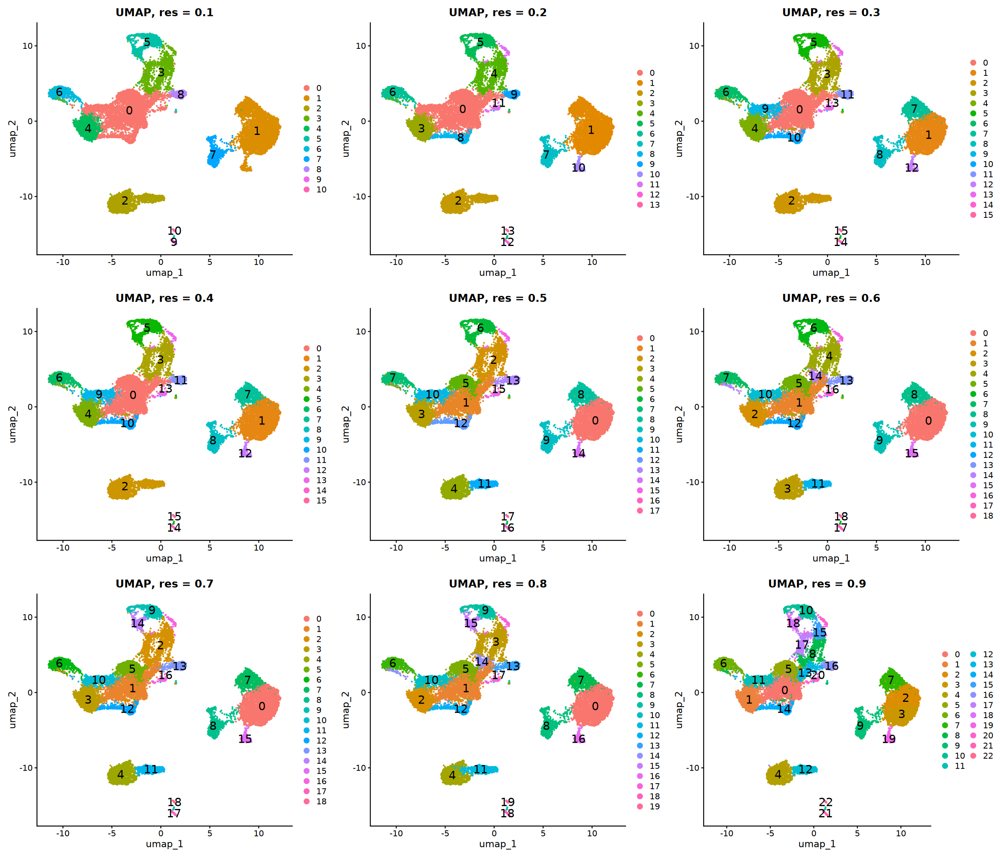

In [114]:
options(repr.plot.width = 21, repr.plot.height = 18)
plot_grid(plotlist = cluster_list$plot_umap_list, ncol = 3)

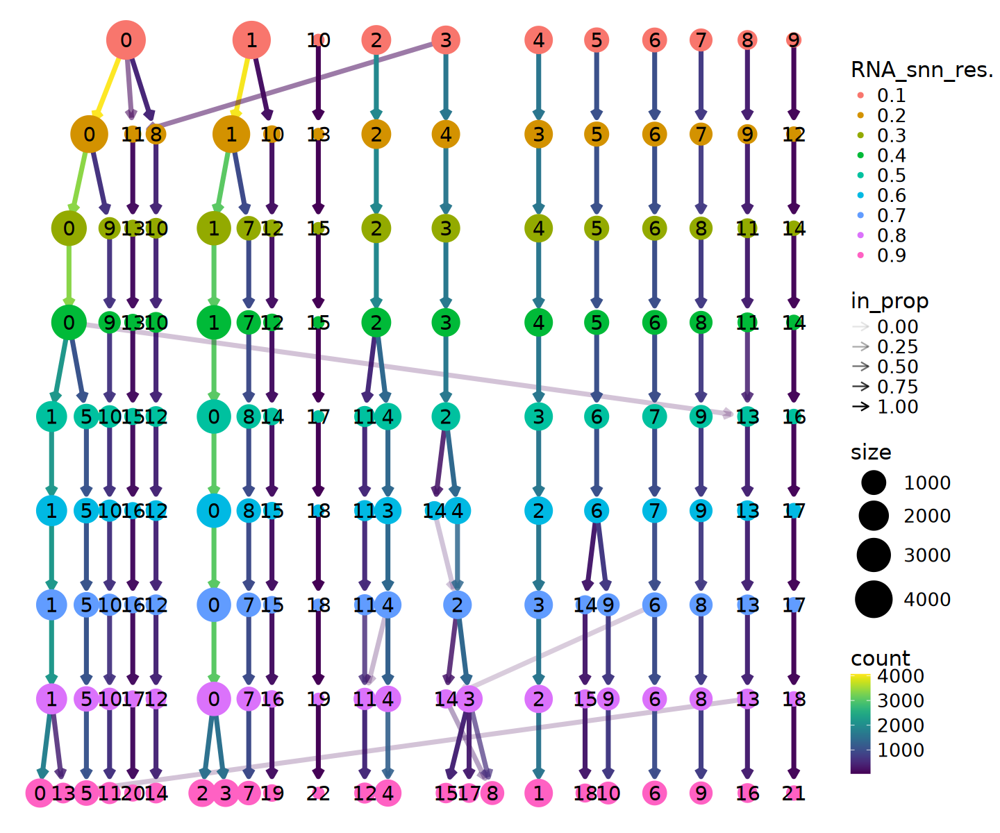

In [115]:
options(repr.plot.width = 12, repr.plot.height = 10)
cluster_list$cluster_tree

In [116]:
sc.inte <- FindClusters(sc.inte, resolution = 0.7, verbose = FALSE)

## 3). Non-linear embedding

In [117]:
# n.neighbors 5 ~ 50, 30
# min.dist 0.001 ~ 0.5, 0.3
plot_umap_params <- function(obj, dims = 10, nn = 30, md = 0.3) {    
    obj <- RunUMAP(
        obj, dims = 1:dims, reduction = inte_rdc, 
        n.neighbors = nn, min.dist = md, verbose = FALSE)
    DimPlot(obj, reduction = "umap", group.by = "seurat_clusters",
            label = TRUE, label.size = 6, repel = FALSE) +
        ggtitle(paste0("n.neighbors = ", nn, "\nmin.dist = ", md))
}

In [118]:
p1 <- lapply(c(10, 30, 50), plot_umap_params, obj = sc.inte, dims = nPCs, md = 0.3)
p2 <- lapply(c(0.01, 0.3, 0.5), plot_umap_params, obj = sc.inte, dims = nPCs, nn = 30)

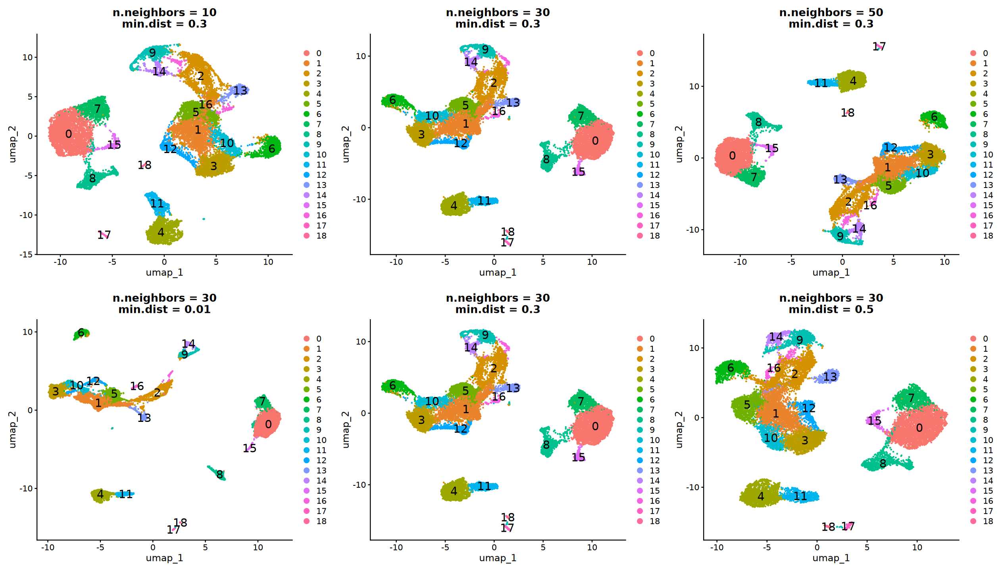

In [119]:
options(repr.plot.width = 21, repr.plot.height = 12)
plot_grid(plot_grid(plotlist = p1, ncol = 3),
          plot_grid(plotlist = p2, ncol = 3), ncol = 1)

In [120]:
# perplexity 5 ~ 50, 30
plot_tsne_params <- function(obj, dims = 10, perplexity = 30) {    
    obj <- RunTSNE(
        obj, dims = 1:dims, reduction = inte_rdc, 
        perplexity = perplexity, verbose = FALSE)
    DimPlot(obj, reduction = "tsne", group.by = "seurat_clusters",
            label = TRUE, label.size = 6, repel = FALSE) +
        ggtitle(paste0("perplexity = ", perplexity))
}

In [121]:
p1 <- lapply(c(10, 30, 50), plot_tsne_params, obj = sc.inte, dims = nPCs)

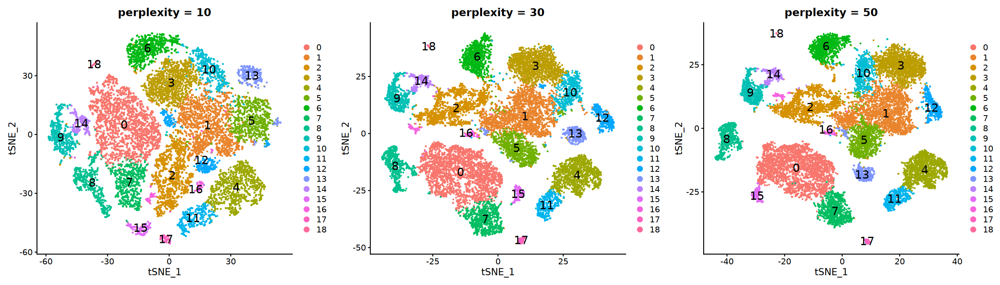

In [122]:
options(repr.plot.width = 21, repr.plot.height = 6)
plot_grid(plotlist = p1, ncol = 3)

In [123]:
sc.inte <- RunUMAP(
    sc.inte, dims = 1:nPCs, reduction = inte_rdc,
    n.neighbors = 30, min.dist = 0.3, verbose = FALSE)

In [124]:
sc.inte <- RunTSNE(
    sc.inte, dims = 1:nPCs, reduction = inte_rdc, 
    perplexity = 30, verbose = FALSE)

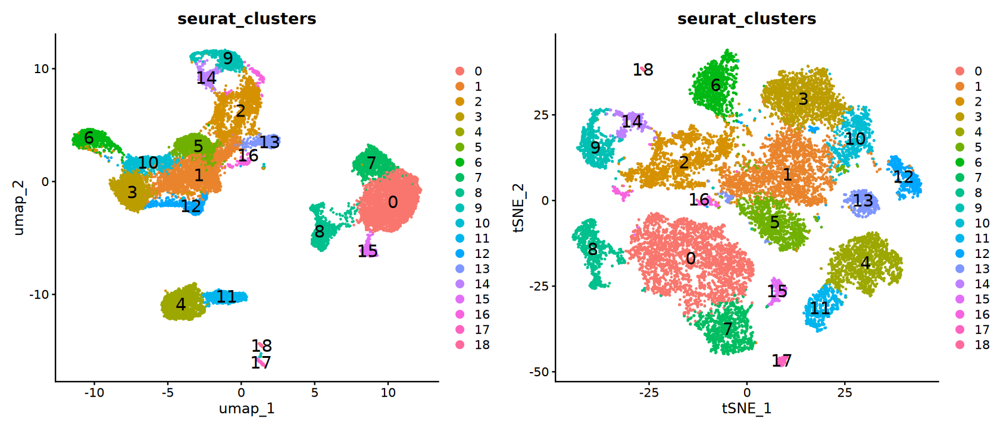

In [125]:
p1 <- DimPlot(
    sc.inte, reduction = "umap", group.by = "seurat_clusters", 
    label = TRUE, label.size = 6, repel = FALSE)
p2 <- DimPlot(
    sc.inte, reduction = "tsne", group.by = "seurat_clusters", 
    label = TRUE, label.size = 6, repel = FALSE)

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

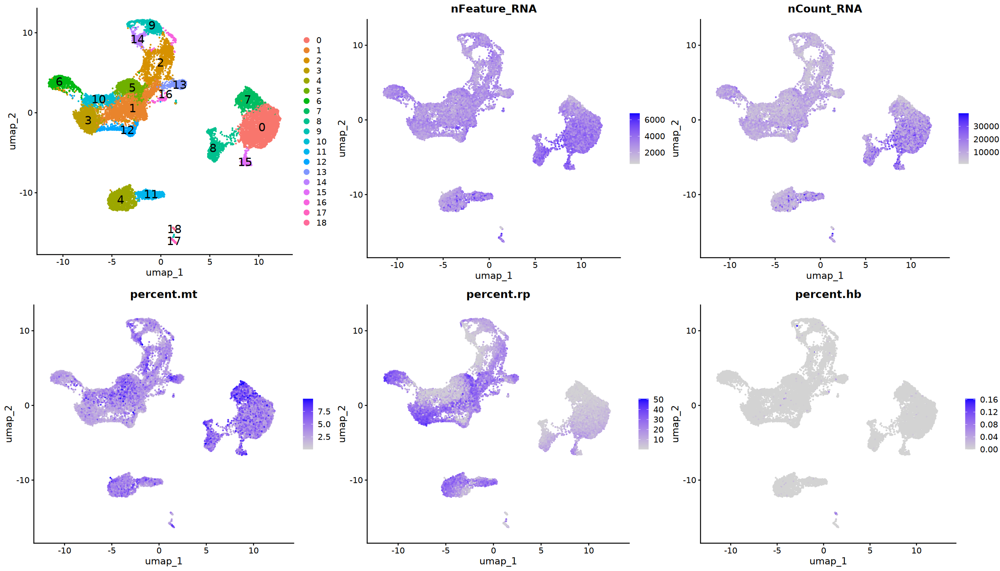

In [126]:
p1 <- DimPlot(
    sc.inte, reduction = "umap", combine = FALSE,
    group.by = c("orig.ident", "seurat_clusters", "Phase"))
p2 <- DimPlot(
    sc.inte, reduction = "umap", combine = FALSE,
    label = TRUE, label.size = 6)
p3 <- FeaturePlot(
    sc.inte, reduction = "umap", combine = FALSE,
    features = c("nFeature_RNA", "nCount_RNA"))
p4 <- FeaturePlot(
    sc.inte, reduction = "umap", combine = FALSE,
    features = c("percent.mt", "percent.rp", "percent.hb", 
                 "S.Score", "G2M.Score", "Dis.Score"))

options(repr.plot.width = 21, repr.plot.height = 24)
plot_grid(plotlist = c(p1, p2, p3, p4), ncol = 3)

In [128]:
sc.inte

An object of class Seurat 
54683 features across 17434 samples within 3 assays 
Active assay: RNA (27812 features, 3000 variable features)
 3 layers present: data, counts, scale.data
 2 other assays present: SCT, mnn.reconstructed
 9 dimensional reductions calculated: pca, cca, rpca, harmony, mnn, scvi, ligerInmf, umap, tsne

## Evaluation Integration (Part 2)

Silhouette (biological conservation)

In [129]:
sil <- cluster::silhouette(
    Idents(sc.inte) |> as.numeric(), 
    dist(Embeddings(sc.inte, reduction = inte_rdc)))
message("Mean cluster silhouette:", round(mean(sil[, 3]), 4))

Mean cluster silhouette:0.2299



Graph Connectivity

In [130]:
# Construct a kNN graph
knn_graph <- FNN::get.knn(
    Embeddings(sc.inte, reduction = inte_rdc),
    k = 30, algorithm = "cover_tree")

In [131]:
# Calculate the "internal neighbor ratio" for each cluster
clusters <- Idents(sc.inte)
conn_ratio <- sapply(unique(clusters), function(cl){
    idx <- which(clusters == cl)
    neighbors <- knn_graph$nn.index[idx, ]
    mean(apply(neighbors, 1, function(x) sum(x %in% idx) / 30))
})

In [132]:
message("Graph connectivity:", round(mean(conn_ratio), 4))

Graph connectivity:0.9216



k-Nearest neighbor batch-effect test ([kBET](https://github.com/theislab/kBET)), which measures batch mixing at the local level. After SVD-based dimension reduction, the k-nearest neighbors around each data point are selected to compute its local batch label distribution. Then, 10% of the data points are randomly selected to test the local batch label distribution against the global distribution. The null hypothesis of all batches being well mixed is not rejected if the local distribution is sufficiently similar to the global distribution. The fraction of rejections ranges from 0 to 1. If the fraction of rejections is close to zero, this signifies that the batches are well mixed.

- Büttner, M., Miao, Z., Wolf, F.A. et al. A test metric for assessing single-cell RNA-seq batch correction. Nat Methods 16, 43–49 (2019). https://doi.org/10.1038/s41592-018-0254-1

In [133]:
suppressPackageStartupMessages(library(kBET))

In [134]:
sc.subset <- subset(sc.inte, idents = "0")

In [135]:
kbet_res <- kBET(
    df = Embeddings(sc.subset, reduction = inte_rdc),
    batch = sc.subset@meta.data[, "orig.ident"], plot = FALSE)

In [136]:
summary(kbet_res$stats$kBET.observed)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 0.9967  1.0000  1.0000  0.9998  1.0000  1.0000 

# 7. Cluster Biomarkers

## Marker Identification

In [137]:
sc.markers <- FindAllMarkers(
    sc.inte, logfc.threshold = log2(1.2), min.pct = 0.25, 
    only.pos = FALSE, verbose = FALSE)

In [138]:
sc.markers.filt <- sc.markers |> 
    filter(p_val_adj < 0.01, 
           avg_log2FC > log2(1.2), 
           pct.1 - pct.2 > 0.2)

In [139]:
sc.markers.filt |> 
    group_by(cluster) |> 
    summarise(length(gene)) |>
    t()

cluster,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
length(gene),2043,167,143,212,340,204,402,679,1638,347,150,576,158,210,240,1832,133,1595,526


In [140]:
top10 <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(10, wt = avg_log2FC)

top3 <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(3, wt = avg_log2FC)

## Visualization

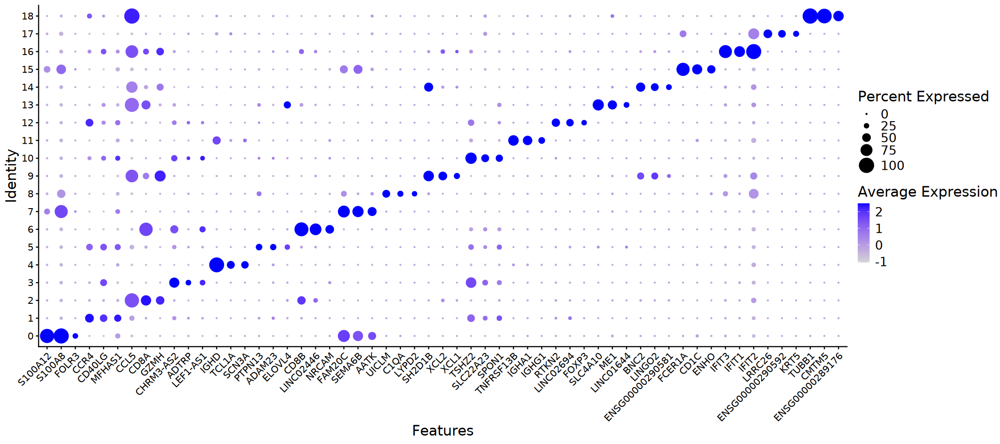

In [141]:
options(repr.plot.width = 18, repr.plot.height = 8)
DotPlot(sc.inte, features = unique(top3$gene), dot.scale = 8) + 
    RotatedAxis() + 
    theme(axis.title = element_text(size = 18),
          axis.text = element_text(size = 12),
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16))

In [142]:
plot_dir <- file.path(
    data_dir, "visualization", "p7.1_cluster_top10_genes")

if (!dir.exists(plot_dir)) {
    dir.create(plot_dir, recursive = TRUE)
}

In [143]:
for (index in seq(1:length(top10$gene))) {
    p1 <- VlnPlot(sc.inte, features = top10$gene[index])
    p2 <- FeaturePlot(
        sc.inte, reduction = "umap", features = top10$gene[index])
    p3 <- FeaturePlot(
        sc.inte, reduction = "tsne", features = top10$gene[index])
    pg <- plot_grid(p1, plot_grid(p2, p3, ncol = 2), ncol = 1)
    
    file.path(plot_dir, paste0(
        "cluster_", top10$cluster[index], "_", top10$gene[index], ".png")) |>
        ggsave(plot = pg, width = 9, height = 8)
}

In [144]:
ht <- DoHeatmap(sc.comb, features = top3$gene, 
                slot = "scale.data", size = 8) +
    # scale_fill_gradientn(colors = PurpleAndYellow()) +
    theme(axis.text = element_text(size = 12),
          legend.title = element_text(size = 18), 
          legend.text = element_text(size = 16))

file.path(data_dir, "visualization", "p7.2_DEG_Top3_DoHeatmap.png") |>
    ggsave(plot = ht, width = 24, height = 16)

In [145]:
saveRDS(sc.inte, file.path(
    data_dir, "result", "s7_cluster_seurat_V5.rds"))

# 8. Cell-type Annotation

Picking joint bandwidth of 0.0688

Picking joint bandwidth of 0.0116

Picking joint bandwidth of 0.0224

Picking joint bandwidth of 0.045

Picking joint bandwidth of 0.0487

Picking joint bandwidth of 0.0718



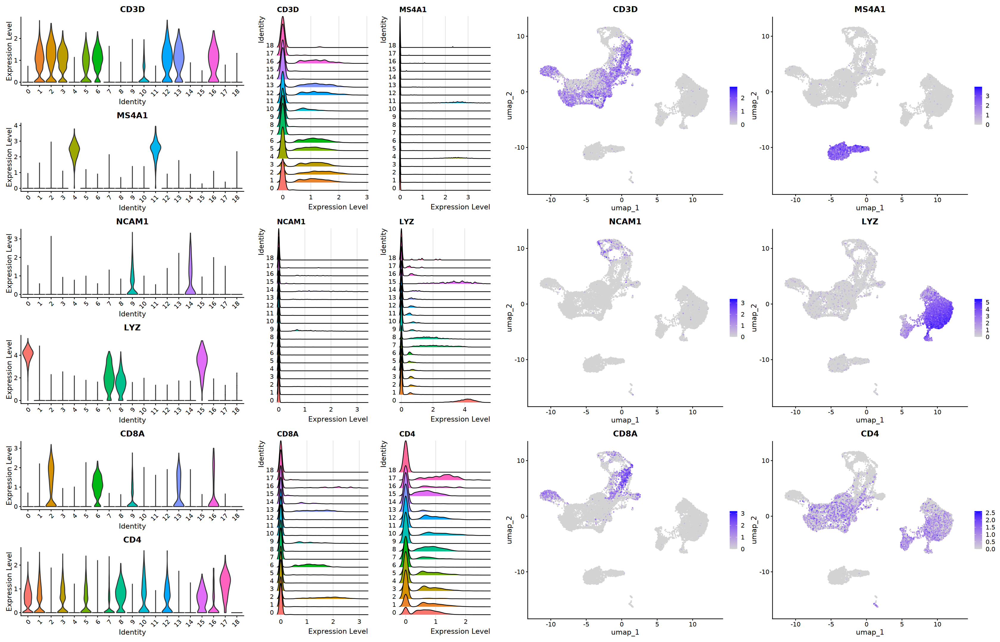

In [146]:
geneset <- c("CD3D", "MS4A1", "NCAM1", "LYZ", "CD8A", "CD4")
p1 <- VlnPlot(
    sc.inte, features = geneset, ncol = 1, pt.size = 0)
p2 <- RidgePlot(
    sc.inte, features = geneset, ncol = 2)
p3 <- FeaturePlot(
    sc.inte, reduction = "umap", features = geneset, ncol = 2)

options(repr.plot.width = 28, repr.plot.height = 18)
plot_grid(p1, p2, p3, ncol = 3, rel_widths = c(1, 1, 2))

## Manual Annotation

### Marker genes

In [147]:
gene_list <- sc.markers.filt |> 
    group_by(cluster) |> 
    top_n(10, wt = avg_log2FC) |>
    summarise(genes = paste0('"', gene, '"', collapse = ", ")) |>
    mutate(out = paste0("cluster_", cluster, ": ", genes)) |> 
    pull(out)

In [148]:
gene_list |> cat(sep = "\n")

cluster_0: "S100A12", "CD14", "S100A8", "ENSG00000257764", "S100A9", "RBP7", "CLEC4E", "MPHOSPH10P1", "FCGR1A", "FOLR3"
cluster_1: "TRAT1", "CD5", "CCR4", "ICOS", "CD40LG", "PGAP1", "DUSP4", "PASK", "ST8SIA1", "MFHAS1"
cluster_2: "CCL5", "CD8A", "C1orf21", "GZMH", "MCOLN2", "TRGC2", "KLRG1", "KLRC4", "EOMES", "GZMK"
cluster_3: "LEF1", "FHIT", "MAL", "CHRM3-AS2", "PRKCQ-AS1", "AK5", "ADTRP", "ENSG00000289707", "LEF1-AS1", "LYPD3"
cluster_4: "IGHD", "COL19A1", "FCRL1", "FCER2", "KHDRBS2", "LIX1-AS1", "TCL1A", "SCN3A", "LINC02397", "KLHL14"
cluster_5: "KIF5C", "CCR6", "PTPN13", "ENSG00000227240", "ADAM23", "TCP10L", "TNFRSF4", "ELOVL4", "NEO1", "ZDHHC11B"
cluster_6: "CD8B", "LINC02446", "NELL2", "APBA2", "NRCAM", "PTPRK", "S100B", "LRRN3", "ENSG00000290109", "TTTY14"
cluster_7: "FCAR", "SLC22A4", "FAM20C", "SEMA6B", "NLRP12", "AATK", "MN1", "ADORA2B", "STAB1", "TNS1"
cluster_8: "CDKN1C", "ENSG00000287682", "RDUR", "UICLM", "LINC02432", "PPP1R17", "BATF3", "C1QA", "KNDC1", "LYPD2"
cluster_

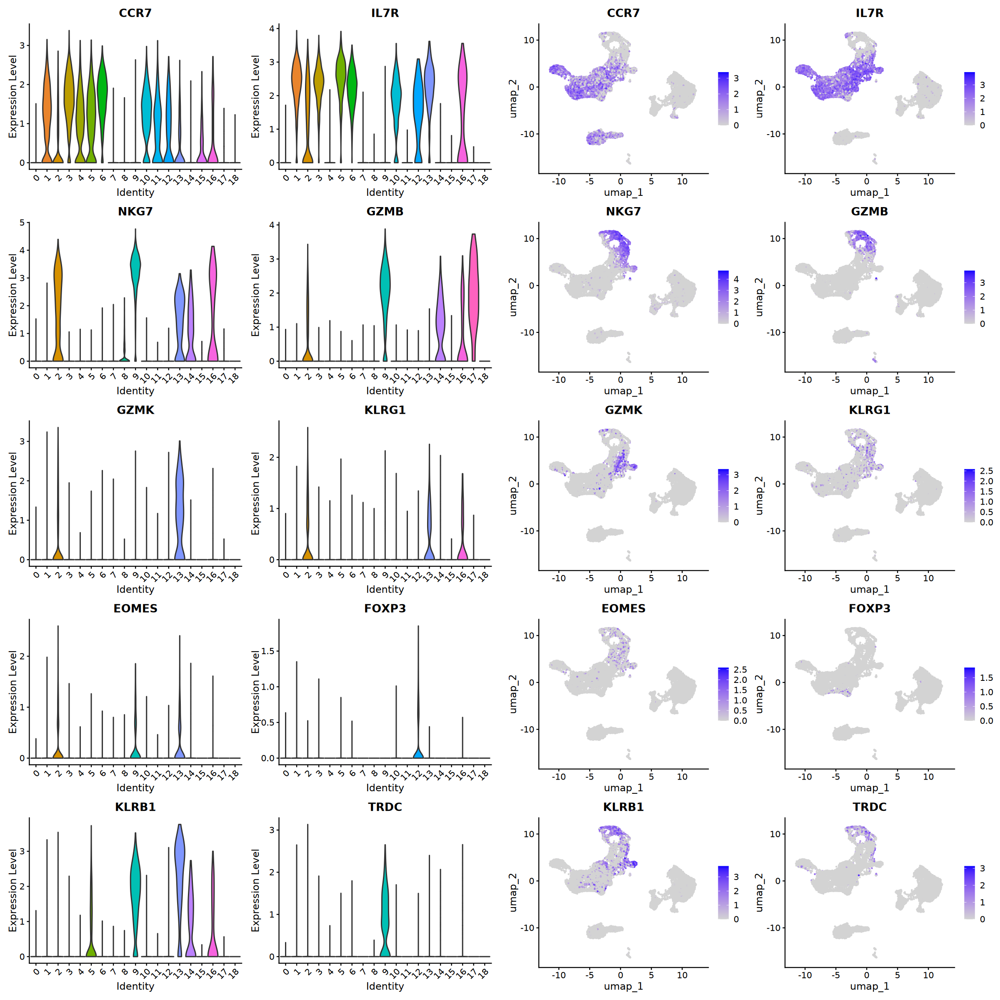

In [149]:
geneset <- c("CCR7", "IL7R", "NKG7", "GZMB", "GZMK", 
             "KLRG1", "EOMES", "FOXP3", "KLRB1", "TRDC")
p1 <- VlnPlot(
    sc.inte, features = geneset, ncol = 2, pt.size = 0)
p2 <- FeaturePlot(
    sc.inte, features = geneset, reduction = "umap", ncol = 2)

options(repr.plot.width = 20, repr.plot.height = 20)
plot_grid(p1, p2, ncol = 2, rel_widths = c(1, 1))

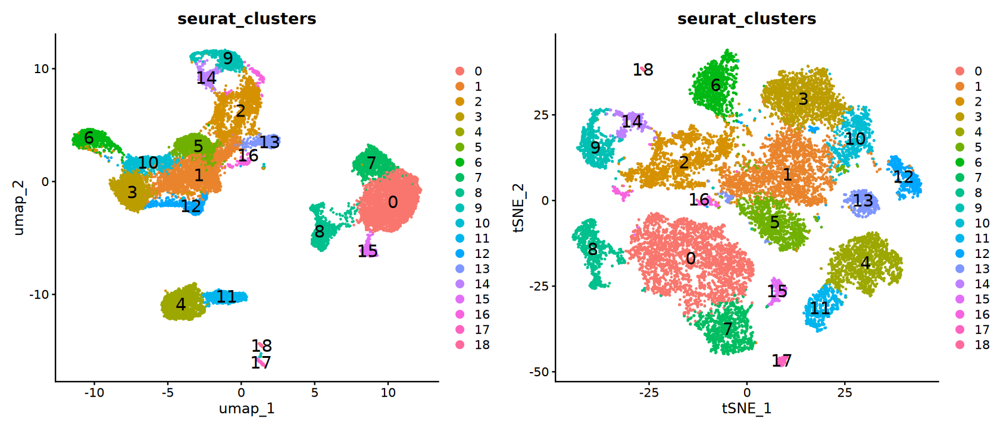

In [150]:
p1 <- DimPlot(
    sc.inte, reduction = "umap", group.by = "seurat_clusters", 
    label = TRUE, label.size = 6, repel = FALSE)
p2 <- DimPlot(
    sc.inte, reduction = "tsne", group.by = "seurat_clusters", 
    label = TRUE, label.size = 6, repel = FALSE)

options(repr.plot.width = 14, repr.plot.height = 6)
plot_grid(p1, p2, ncol = 2)

#### AI modes

In [151]:
# Cell annotation with ChatGPT assistance
cluster2celltype <- c(
    "0" = "Monocytes",
    "1" = "Activated CD4 T",
    "2" = "Cytotoxic CD8 T",
    "3" = "Naïve CD4 T",
    "4" = "Naïve B",
    "5" = "Activated CD4 T",
    "6" = "Naïve CD8 T",
    "7" = "Monocytes",
    "8" = "cDC1",
    "9" = "NK",
    "10" = "Naïve CD4 T",
    "11" = "Plasma Cells",
    "12" = "Treg",
    "13" = "MAIT",
    "14" = "NK",
    "15" = "cDC2",
    "16" = "ISG",
    "17" = "Epithelial-like",
    "18" = "Platelets")

In [152]:
sc.inte@meta.data$ChatGPT_Anno <- 
    cluster2celltype[as.character(sc.inte$seurat_clusters)]
# Idents(sc.inte) <- sc.inte$seurat_clusters
# sc.inte <- RenameIdents(sc.inte, cluster2celltype)

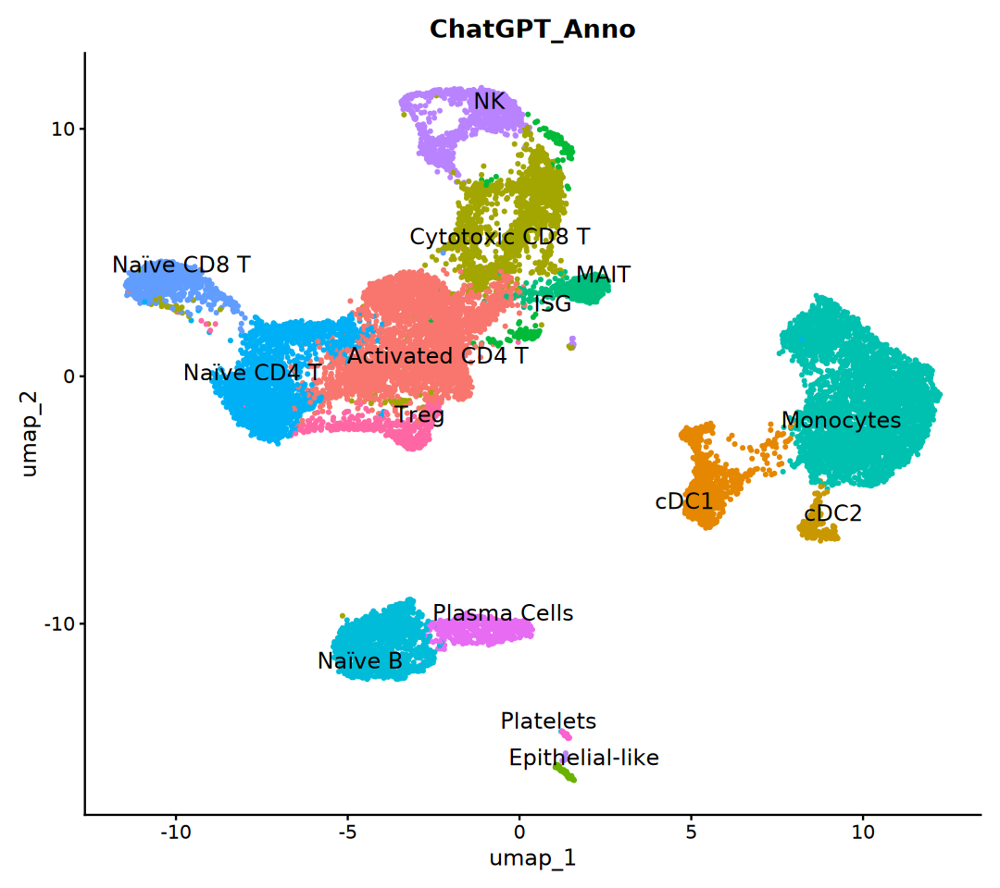

In [153]:
options(repr.plot.width = 9, repr.plot.height = 8)
DimPlot(sc.inte, reduction = "umap", group.by = "ChatGPT_Anno", 
        label = TRUE, repel = TRUE,
        pt.size = 0.5, label.size = 5) + 
    NoLegend()